<a href="https://colab.research.google.com/github/shiva-learns/Machine-Learning/blob/main/Supervised%20Learning/Linear%20Regression/Multicollinearity_Assessment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Use the famous boston dataset and find out if there is multicollinearity or not. If there is multicollinearity try to remove it with help of steps taught in the session.

In [1]:
# Link - https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv

In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"

df = pd.read_csv(url)

df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [3]:
df.shape

(506, 14)

<Axes: >

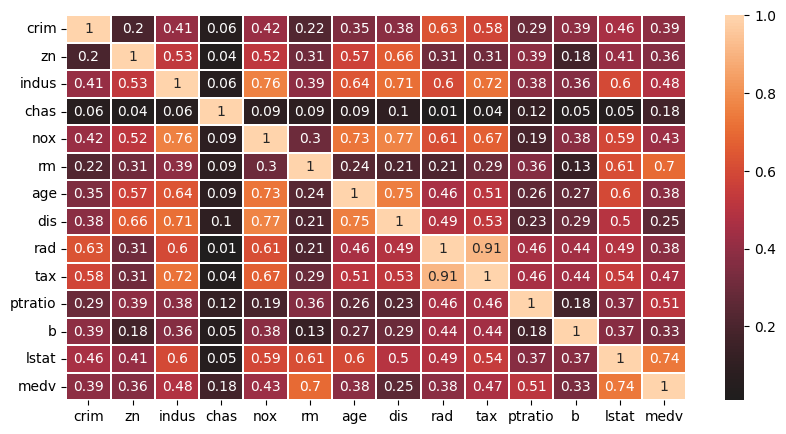

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,5))
sns.heatmap(df.corr().abs().round(2),center=0,annot=True,linewidths=0.2)

In [16]:
correlated_cols = []
corr = df.corr().abs()
for i in range(len(corr.columns)):
  for j in range(i+1,len(corr.columns)):
    if corr.iloc[i,j] > 0.8:
      correlated_cols.append((corr.columns[i],corr.columns[j],round(corr.iloc[i,j],3)))


In [30]:
df_filtered_corr = df.drop(columns=['rad'])
df_filtered_corr

,crim,zn,indus,chas,nox,rm,age,dis,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,273,21.0,393.45,6.48,22.0


In [19]:
df.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'medv'],
      dtype='object')

In [29]:
# Using VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor


X = df.drop(columns=['medv'],axis=1)

vif = pd.DataFrame()
vif['Feature'] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values,i) for i in range(X.shape[1])]

vif

,Feature,VIF
0,crim,1.792192
1,zn,2.298758
2,indus,3.991596
3,chas,1.073995
4,nox,4.393720
5,rm,1.933744
6,age,3.100826
7,dis,3.955945
8,rad,7.484496
9,tax,9.008554


In [36]:
vif_threshold = 5
high_vif_features = vif[vif['VIF'] > vif_threshold]['Feature'].values

df.drop(high_vif_features,axis=1)

,crim,zn,indus,chas,nox,rm,age,dis,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,21.0,393.45,6.48,22.0


In [37]:
X = df.drop('medv',axis=1)
import numpy as np

condition_number = np.linalg.cond(X)
print("Condition Number:", condition_number)

# Multicollinearity Exist

Condition Number: 8497.936303845774


In [50]:
import statsmodels.api as sm

# Add a constant term to the predictor variables
data_with_constant_all = sm.add_constant(df.drop('medv', axis=1))


# Create and fit an OLS model using all three predictor variables
model_all = sm.OLS(df['medv'], data_with_constant_all).fit()

# Print the summary for the model with all predictors
print("Regression summary for the model with all predictors:")
print(model_all.summary())



Regression summary for the model with all predictors:
                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.741
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     108.1
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          6.72e-135
Time:                        05:44:31   Log-Likelihood:                -1498.8
No. Observations:                 506   AIC:                             3026.
Df Residuals:                     492   BIC:                             3085.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------

In [51]:
import statsmodels.api as sm

# Add a constant term to the predictor variables
data_with_constant_all = sm.add_constant(df_filtered_corr.drop('medv', axis=1))


# Create and fit an OLS model using all three predictor variables
model_all = sm.OLS(df['medv'], data_with_constant_all).fit()

# Print the summary for the model with all predictors
print("Regression summary for the model with all predictors:")
print(model_all.summary())



Regression summary for the model with all predictors:
                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.729
Model:                            OLS   Adj. R-squared:                  0.723
Method:                 Least Squares   F-statistic:                     110.8
Date:                Sun, 18 Oct 2026   Prob (F-statistic):          1.92e-131
Time:                        05:44:51   Log-Likelihood:                -1509.5
No. Observations:                 506   AIC:                             3045.
Df Residuals:                     493   BIC:                             3100.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------